In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Find the attached Kaggle dataset
files = glob.glob(
    "/kaggle/input/**/creditcard.csv",
    recursive=True
)

if not files:
    raise FileNotFoundError(
        "Dataset not found. Use Add Input to attach "
        "the Credit Card Fraud Detection dataset."
    )

df = pd.read_csv(files[0])

print("FINANCIAL FRAUD ANALYTICS")
print("=" * 40)
print("Dataset shape:", df.shape)
print("\nFirst 5 transactions:")
display(df.head())

print("\nMissing values:", df.isnull().sum().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nFraud class distribution:")
display(df["Class"].value_counts().rename(
    index={0: "Legitimate", 1: "Fraud"}
))

print("\nFraud percentage:",
      round(df["Class"].mean() * 100, 3), "%")

FINANCIAL FRAUD ANALYTICS
Dataset shape: (284807, 31)

First 5 transactions:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Missing values: 0

Duplicate rows: 1081

Fraud class distribution:


Class
Legitimate    284315
Fraud            492
Name: count, dtype: int64


Fraud percentage: 0.173 %


FRAUDSHIELD AI | DATA QUALITY REPORT
Original rows: 284807
Rows after deduplication: 283726
Duplicates removed: 1081
Missing values: 0
Remaining duplicate rows: 0

Transaction class distribution:
Legitimate: 283,253 (99.833%)
Fraud:      473 (0.167%)

Transaction amount summary:


,count,mean,median,min,max
Class,,,,,
Legitimate,283253,88.41,22.00,0.0,25691.16
Fraud,473,123.87,9.82,0.0,2125.87


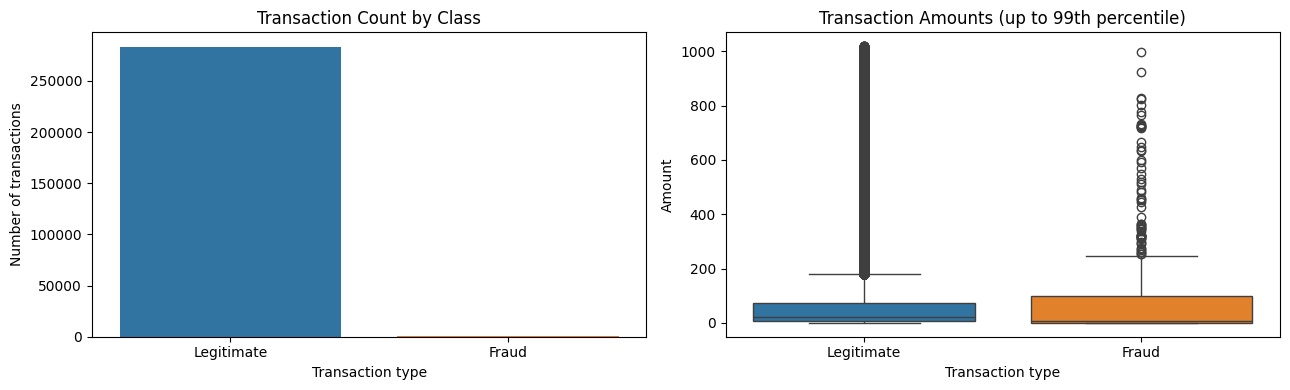

In [2]:

# FraudShield AI — Step 2: Data Cleaning & Initial Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preserve the original dataset
raw_df = df.copy()

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

print("FRAUDSHIELD AI | DATA QUALITY REPORT")
print("=" * 45)
print("Original rows:", len(raw_df))
print("Rows after deduplication:", len(df))
print("Duplicates removed:", len(raw_df) - len(df))
print("Missing values:", df.isnull().sum().sum())
print("Remaining duplicate rows:", df.duplicated().sum())

# Class distribution
class_counts = df["Class"].value_counts().sort_index()
class_pct = df["Class"].value_counts(normalize=True).sort_index() * 100

print("\nTransaction class distribution:")
print(f"Legitimate: {class_counts.get(0, 0):,} "
      f"({class_pct.get(0, 0):.3f}%)")
print(f"Fraud:      {class_counts.get(1, 0):,} "
      f"({class_pct.get(1, 0):.3f}%)")

# Fraud vs legitimate transaction amounts
print("\nTransaction amount summary:")
display(
    df.groupby("Class")["Amount"]
      .agg(["count", "mean", "median", "min", "max"])
      .rename(index={0: "Legitimate", 1: "Fraud"})
      .round(2)
)

# Visual 1: Class distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(
    data=df,
    x="Class",
    hue="Class",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Transaction Count by Class")
axes[0].set_xticks([0, 1], ["Legitimate", "Fraud"])
axes[0].set_xlabel("Transaction type")
axes[0].set_ylabel("Number of transactions")

# Visual 2: Amount distribution, capped at 99th percentile for readability
amount_cap = df["Amount"].quantile(0.99)
plot_df = df[df["Amount"] <= amount_cap]

sns.boxplot(
    data=plot_df,
    x="Class",
    y="Amount",
    hue="Class",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Transaction Amounts (up to 99th percentile)")
axes[1].set_xticks([0, 1], ["Legitimate", "Fraud"])
axes[1].set_xlabel("Transaction type")
axes[1].set_ylabel("Amount")

plt.tight_layout()
plt.show()


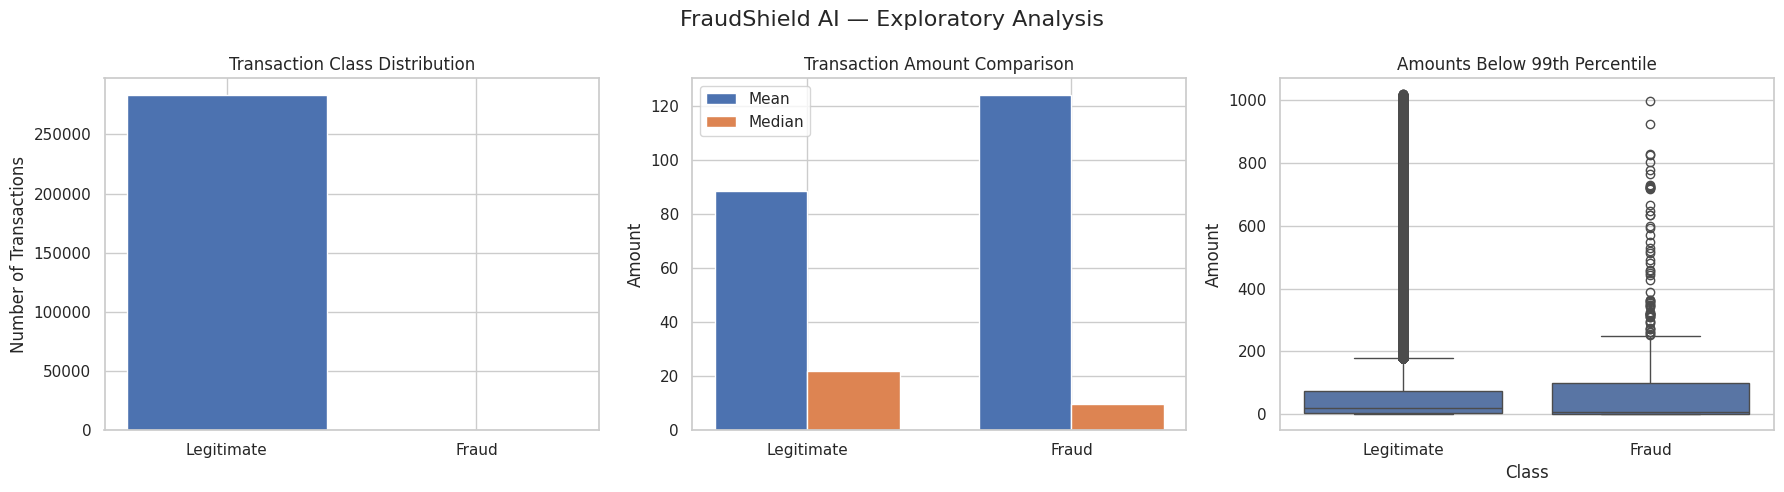

KEY FINDINGS
----------------------------------------
Transactions analyzed: 283,726
Fraud transactions: 473
Fraud rate: 0.167%
Legitimate mean amount: 88.41
Fraud mean amount: 123.87
Legitimate median amount: 22.00
Fraud median amount: 9.82


In [3]:

# FraudShield AI | Step 3: Exploratory Data Analysis

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

sns.set_theme(style="whitegrid", palette="deep")

# 1. Transaction class distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

class_counts = df["Class"].value_counts().sort_index()

axes[0].bar(
    ["Legitimate", "Fraud"],
    [class_counts.get(0, 0), class_counts.get(1, 0)]
)
axes[0].set_title("Transaction Class Distribution")
axes[0].set_ylabel("Number of Transactions")

# 2. Average and median transaction amounts
amount_stats = df.groupby("Class")["Amount"].agg(["mean", "median"])
x = np.arange(2)
width = 0.35

axes[1].bar(
    x - width/2, amount_stats["mean"].values,
    width, label="Mean"
)
axes[1].bar(
    x + width/2, amount_stats["median"].values,
    width, label="Median"
)
axes[1].set_xticks(x, ["Legitimate", "Fraud"])
axes[1].set_title("Transaction Amount Comparison")
axes[1].set_ylabel("Amount")
axes[1].legend()

# 3. Amount distribution (limit extreme values for readability)
cap = df["Amount"].quantile(0.99)
sns.boxplot(
    data=df[df["Amount"] <= cap],
    x="Class", y="Amount",
    ax=axes[2]
)
axes[2].set_xticks([0, 1], ["Legitimate", "Fraud"])
axes[2].set_title("Amounts Below 99th Percentile")
axes[2].set_ylabel("Amount")

plt.suptitle("FraudShield AI — Exploratory Analysis", fontsize=16)
plt.tight_layout()
plt.show()

# Key findings from the current dataset
print("KEY FINDINGS")
print("-" * 40)
print(f"Transactions analyzed: {len(df):,}")
print(f"Fraud transactions: {(df['Class'] == 1).sum():,}")
print(f"Fraud rate: {df['Class'].mean() * 100:.3f}%")
print(f"Legitimate mean amount: {df.loc[df.Class == 0, 'Amount'].mean():.2f}")
print(f"Fraud mean amount: {df.loc[df.Class == 1, 'Amount'].mean():.2f}")
print(f"Legitimate median amount: {df.loc[df.Class == 0, 'Amount'].median():.2f}")
print(f"Fraud median amount: {df.loc[df.Class == 1, 'Amount'].median():.2f}")


FRAUDSHIELD AI | BASELINE MODEL

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56651
       Fraud       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746

Average Precision (PR-AUC): 0.6719
ROC-AUC: 0.9657


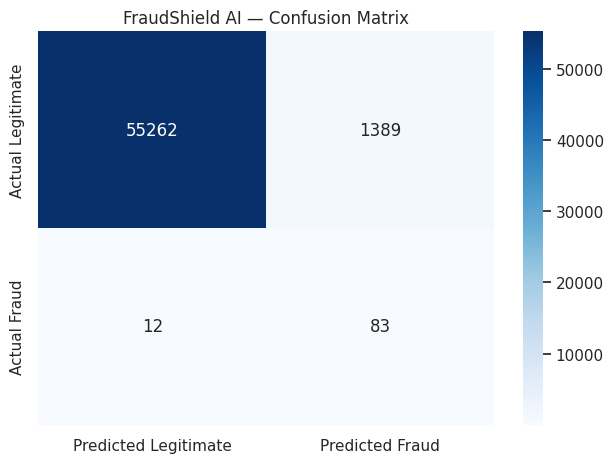

In [4]:

# FraudShield AI | Step 4: Baseline ML Model

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Separate features and target
X = df.drop(columns=["Class"])
y = df["Class"]

# Keep the test set separate and preserve class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scale features and fit the baseline model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

model.fit(X_train, y_train)

# Evaluate on unseen test data
y_pred = model.predict(X_test)
y_score = model.predict_proba(X_test)[:, 1]

print("FRAUDSHIELD AI | BASELINE MODEL")
print("=" * 40)
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("Average Precision (PR-AUC):",
      round(average_precision_score(y_test, y_score), 4))
print("ROC-AUC:",
      round(roc_auc_score(y_test, y_score), 4))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted Legitimate", "Predicted Fraud"],
    yticklabels=["Actual Legitimate", "Actual Fraud"]
)
plt.title("FraudShield AI — Confusion Matrix")
plt.tight_layout()
plt.show()


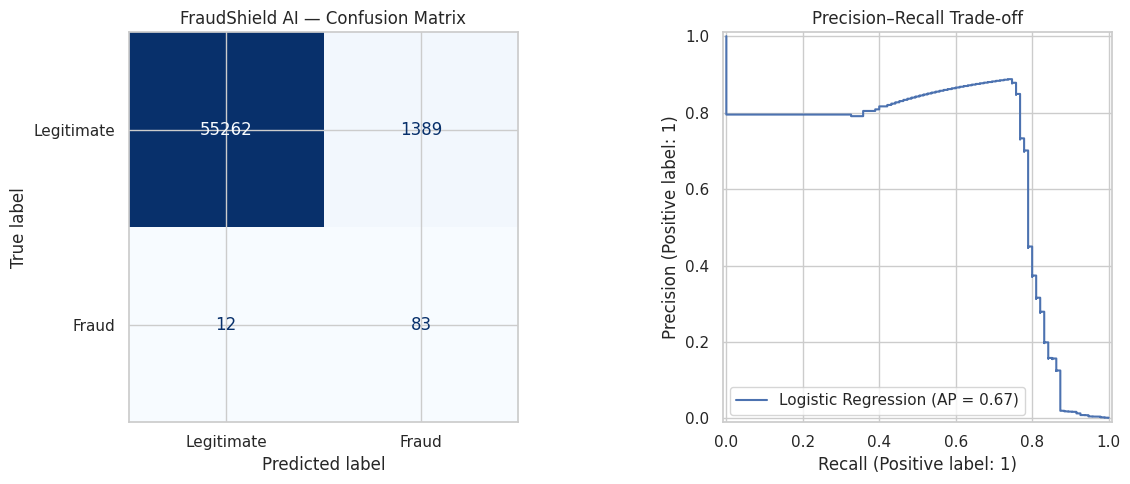

Baseline fraud recall: 0.874
Baseline fraud precision: 0.056
Baseline fraud F1: 0.106


In [5]:

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    precision_recall_curve,
    f1_score
)
import matplotlib.pyplot as plt
import numpy as np

# Visualize model performance
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("FraudShield AI — Confusion Matrix")

PrecisionRecallDisplay.from_predictions(
    y_test, y_score,
    ax=axes[1],
    name="Logistic Regression"
)
axes[1].set_title("Precision–Recall Trade-off")

plt.tight_layout()
plt.show()

print("Baseline fraud recall:",
      round(np.mean(y_pred[y_test == 1] == 1), 3))
print("Baseline fraud precision:",
      round(np.sum((y_pred == 1) & (y_test == 1)) /
            max(np.sum(y_pred == 1), 1), 3))
print("Baseline fraud F1:",
      round(f1_score(y_test, y_pred), 3))


In [6]:

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
rows = []

for threshold in thresholds:
    pred = (y_score >= threshold).astype(int)

    rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "Flagged transactions": int(pred.sum())
    })

threshold_results = pd.DataFrame(rows)
display(threshold_results.round(3))


,Threshold,Precision,Recall,F1-score,Flagged transactions
0,0.1,0.009,0.937,0.017,10251
1,0.2,0.017,0.916,0.033,5203
2,0.3,0.027,0.874,0.052,3102
3,0.4,0.040,0.874,0.076,2076
4,0.5,0.056,0.874,0.106,1472
5,0.6,0.079,0.874,0.145,1053
6,0.7,0.116,0.874,0.204,717
7,0.8,0.160,0.842,0.269,499
8,0.9,0.262,0.832,0.399,301


In [7]:

from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print("FRAUDSHIELD AI — BUSINESS SUMMARY")
print("=" * 42)
print(f"Test transactions: {len(y_test):,}")
print(f"Actual fraud cases: {int((y_test == 1).sum()):,}")
print(f"Fraud correctly flagged: {tp:,}")
print(f"Fraud missed: {fn:,}")
print(f"Legitimate transactions falsely flagged: {fp:,}")
print(f"Legitimate transactions correctly passed: {tn:,}")
print()
print("Business interpretation:")
print("- Recall measures how many fraud cases were caught.")
print("- Precision measures how many fraud alerts were truly fraud.")
print("- The alert threshold must balance missed fraud and false alarms.")
print("- This is an experimental model, not a deployed banking system.")


FRAUDSHIELD AI — BUSINESS SUMMARY
Test transactions: 56,746
Actual fraud cases: 95
Fraud correctly flagged: 83
Fraud missed: 12
Legitimate transactions falsely flagged: 1,389
Legitimate transactions correctly passed: 55,262

Business interpretation:
- Recall measures how many fraud cases were caught.
- Precision measures how many fraud alerts were truly fraud.
- The alert threshold must balance missed fraud and false alarms.
- This is an experimental model, not a deployed banking system.


,Threshold,Precision,Recall,F1,Alerts
0,0.1,0.009,0.937,0.017,10251
1,0.2,0.017,0.916,0.033,5203
2,0.3,0.027,0.874,0.052,3102
3,0.4,0.040,0.874,0.076,2076
4,0.5,0.056,0.874,0.106,1472
5,0.6,0.079,0.874,0.145,1053
6,0.7,0.116,0.874,0.204,717
7,0.8,0.160,0.842,0.269,499
8,0.9,0.262,0.832,0.399,301


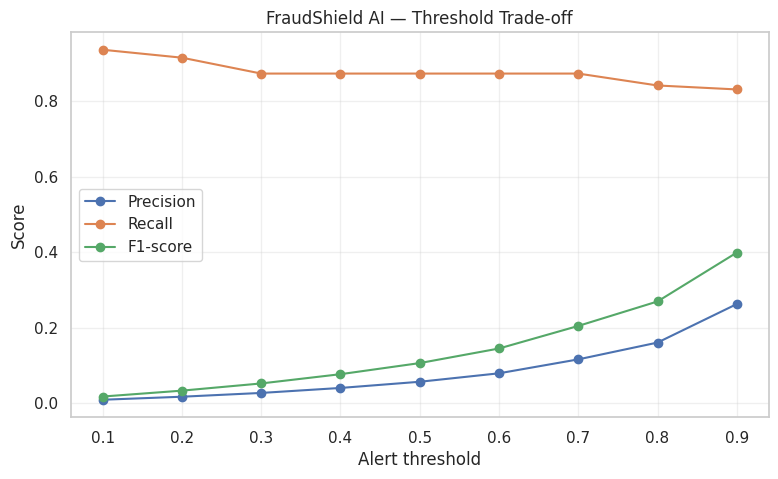

In [8]:

# FraudShield AI — Step 8: Threshold Analysis

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
results = []

for t in thresholds:
    pred = (y_score >= t).astype(int)
    results.append({
        "Threshold": t,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Alerts": int(pred.sum())
    })

threshold_df = pd.DataFrame(results)
display(threshold_df.round(3))

plt.figure(figsize=(9, 5))
plt.plot(threshold_df["Threshold"], threshold_df["Precision"],
         marker="o", label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"],
         marker="o", label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F1"],
         marker="o", label="F1-score")
plt.xlabel("Alert threshold")
plt.ylabel("Score")
plt.title("FraudShield AI — Threshold Trade-off")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [9]:

# FraudShield AI — Business Recommendations

from sklearn.metrics import confusion_matrix, average_precision_score

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print("FRAUDSHIELD AI — FINAL BUSINESS REPORT")
print("=" * 48)
print(f"Test transactions: {len(y_test):,}")
print(f"Fraud correctly detected: {tp}")
print(f"Fraud missed: {fn}")
print(f"False alerts on legitimate transactions: {fp}")
print(f"Legitimate transactions correctly passed: {tn}")
print(f"Fraud recall: {tp / max(tp + fn, 1):.1%}")
print(f"Fraud precision: {tp / max(tp + fp, 1):.1%}")
print(f"Average Precision: {average_precision_score(y_test, y_score):.4f}")

print("\nBUSINESS RECOMMENDATIONS")
print("1. Review high-risk transactions before blocking them.")
print("2. Tune the alert threshold using fraud-loss and review-cost data.")
print("3. Monitor false alerts to avoid unnecessary customer friction.")
print("4. Evaluate recall, precision, F1 and alert volume together.")
print("5. Validate on new data before any real-world deployment.")


FRAUDSHIELD AI — FINAL BUSINESS REPORT
Test transactions: 56,746
Fraud correctly detected: 83
Fraud missed: 12
False alerts on legitimate transactions: 1389
Legitimate transactions correctly passed: 55262
Fraud recall: 87.4%
Fraud precision: 5.6%
Average Precision: 0.6719

BUSINESS RECOMMENDATIONS
1. Review high-risk transactions before blocking them.
2. Tune the alert threshold using fraud-loss and review-cost data.
3. Monitor false alerts to avoid unnecessary customer friction.
4. Evaluate recall, precision, F1 and alert volume together.
5. Validate on new data before any real-world deployment.


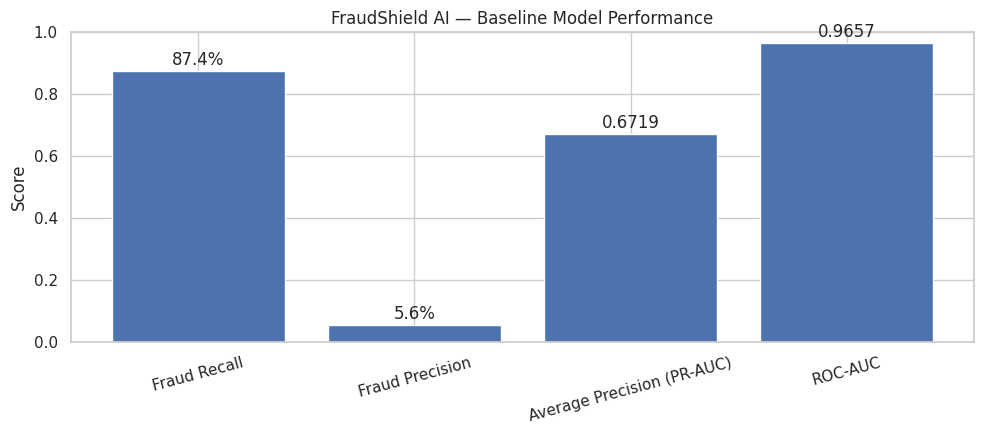

KEY TAKEAWAY
The model catches many fraud cases but generates too many false alerts.
Threshold tuning and business-cost evaluation are the next priorities.


In [10]:

# FraudShield AI — Executive Summary

import matplotlib.pyplot as plt

metrics = {
    "Fraud Recall": 0.874,
    "Fraud Precision": 0.056,
    "Average Precision (PR-AUC)": 0.6719,
    "ROC-AUC": 0.9657
}

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(
    metrics.keys(),
    metrics.values()
)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("FraudShield AI — Baseline Model Performance")
ax.tick_params(axis="x", rotation=15)

for bar, value in zip(bars, metrics.values()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.1%}" if value != 0.6719 and value != 0.9657
        else f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

print("KEY TAKEAWAY")
print("The model catches many fraud cases but generates too many false alerts.")
print("Threshold tuning and business-cost evaluation are the next priorities.")


# Conclusion — FraudShield AI

## 1. Business Problem

Credit card fraud detection is challenging because fraudulent transactions represent a very small fraction of total transactions. Financial institutions need to identify suspicious transactions while minimizing false alerts for legitimate customers.

## 2. Data Preparation

The original dataset contained 284,807 transactions. After removing 1,081 exact duplicate rows, 283,726 records remained. No missing values were detected.

## 3. Model Evaluation

A Logistic Regression baseline was trained using a stratified train-test split. On the held-out test set, it achieved:

- **Fraud recall:** 87.4%
- **Fraud precision:** 5.6%
- **Average Precision (PR-AUC):** 0.6719
- **ROC-AUC:** 0.9657

The model detected 83 of 95 fraud cases in the test set, missed 12, and falsely flagged 1,389 legitimate transactions.

## 4. Business Recommendations

1. Evaluate alert thresholds against fraud losses and manual-review costs.
2. Prioritize high-risk transactions for review rather than automatically blocking them.
3. Monitor false alerts to reduce unnecessary customer friction.
4. Track precision, recall, F1-score, PR-AUC, and alert volume together.
5. Validate performance on newer, independent data before real-world use.

## 5. Limitations

The dataset uses anonymized features, limiting direct interpretation of individual transactions. This baseline is an educational prototype and has not been validated for deployment in a real financial institution.

## 6. Future Improvements

- Compare additional machine learning models.
- Evaluate different alert thresholds.
- Investigate false positives and missed fraud cases.
- Document reproducible experiments and model limitations.
- Develop a dashboard for reviewing flagged transactions.

## Final Takeaway

FraudShield AI demonstrates how data analysis and machine learning can support credit card fraud risk assessment. The baseline model identifies many fraud cases but also produces a high number of false alerts. Further threshold optimization, validation, and business-cost analysis are necessary before practical deployment.


In [11]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Uses the already-trained model and existing test set
fraud_prob = model.predict_proba(X_test)[:, 1]

results = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]:
    pred = (fraud_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Alerts": int(pred.sum())
    })

threshold_df = pd.DataFrame(results)
display(threshold_df.round(3))

,Threshold,Precision,Recall,F1,Alerts
0,0.1,0.009,0.937,0.017,10251
1,0.2,0.017,0.916,0.033,5203
2,0.3,0.027,0.874,0.052,3102
3,0.4,0.040,0.874,0.076,2076
4,0.5,0.056,0.874,0.106,1472
5,0.6,0.079,0.874,0.145,1053
6,0.7,0.116,0.874,0.204,717
7,0.8,0.160,0.842,0.269,499
8,0.9,0.262,0.832,0.399,301


## Threshold Analysis

The threshold comparison shows the trade-off between fraud detection and the number of transactions flagged for review.

- At a threshold of **0.1**, the model flags 10,251 transactions and achieves 93.7% recall, but precision is only 0.9%.
- At a threshold of **0.5**, the model flags 1,472 transactions, with 87.4% recall and 5.6% precision.
- At a threshold of **0.7**, the model flags 717 transactions, with 87.4% recall and 11.6% precision.
- At a threshold of **0.9**, the model flags 301 transactions, with 83.2% recall and 26.2% precision.

### Business Interpretation

Increasing the threshold reduces the number of alerts and improves precision, but may also cause more fraudulent transactions to be missed. The appropriate threshold depends on fraud losses, review capacity, and the cost of false alerts. These results are for an educational model and do not establish a production-ready threshold.
